# Project 3.

Student ID: 11399397

University of Manchester

In the table of contents please turn on heading numbers.

This goal of this project is to develop and demonstrate computational simulation of neutron transport through various shielding materials using Monte Carlo techniques. We aim to investigate how the choice of shielding material and its thickness $L$ affect the rates of absorption, reflection and transmission.

Initialise our python interpreter:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# time and tnrange may not be included in the final draft. However I have used it for optimisation.
from tqdm.notebook import tnrange 
import time

# Generating random numbers.

In this section we investigate the generation of random numbers. The knowledge and methods described will be used for our Monte Carlo Simulations in section 3 and 4.

## Using python's in-built random number generator.

The use of ```np.random.uniform()``` is integral for our Monte Carlo methods. Below we confirm that it does indeed generate random numbers and that the numbers generated are uniform over a chosen range.

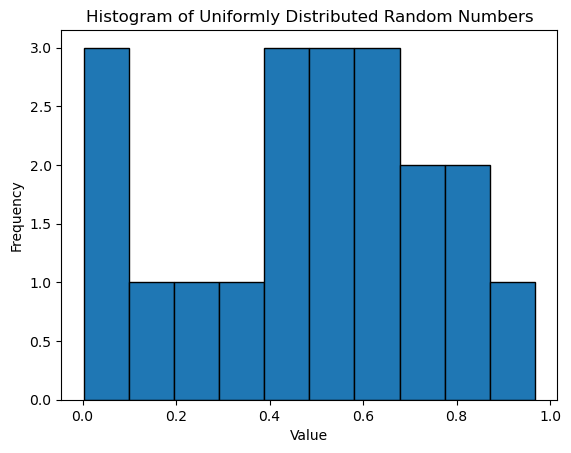

In [2]:
random_number = np.random.uniform() # Is the same as - np.random.uniform(low=0.0, high=1.0) - so it will generate floats between 0 & 1.
#print(random_number)

random_numbers = np.zeros(20) # Creating empty array to put twenty random numbers in.

for i in range(len(random_numbers)):
    random_number = np.random.uniform() # Each loop new random number generated.
    random_numbers[i] = random_number # New random number is added to the array.

# Plot this array to see if it is a uniform distribution
plt.hist(random_numbers, bins=10, edgecolor='black')
plt.title('Histogram of Uniformly Distributed Random Numbers')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

For twenty random numbers generated, the plot's display of uniformity can be volatile. Let us try for ten thousand.

We can also use ```np.random.uniform(size=N)``` to generate an array of N random numbers rather than using the ```for``` loop above.

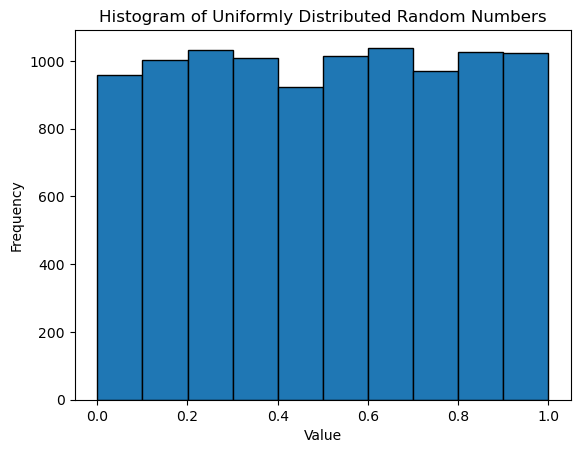

In [3]:
random_numbers = np.random.uniform(0, 1, 10000) # Defining an array of 10,000 random numbers.

# Plot this array to see if it is a uniform distribution.
plt.hist(random_numbers, bins=10, edgecolor='black')
plt.title('Histogram of Uniformly Distributed Random Numbers')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

With more repetitions we can see the uniformity is less volatile. There is an even spread across 0 to 1, suggesting the ```np.random.uniform()``` is reliable.

I will now use ```np.random.uniform()``` & phys20762-code11randssp.ipynb to generate an array of randomly distributed points in 3D ($x$,$y$,$z$). Displaying these points using a scatter plot and checking for spectral issues.

In [4]:
# Note if this code is run after cell 6 it will have issues as x has been defined.

# --- Code from randssp.ipynb.
 
#  RANDSSP Multiplicative congruential uniform random number generator.
#  Based on the parameters used by IBM's Scientific Subroutine Package.
#  The statement
#     r = randssp(m,n)
#  generates an m-by-n random matrix.
#  The function can not accept any other starting seed.
#
#  This function uses the "bad" generator parameters that IBM
#  used in several libraries in the 1960's.  There is a strong
#  serial correlation between three consecutive values.

def randssp(p,q):
    
    global m, a, c, x
        
    try: x
    except NameError:
        m = pow(2, 31)
        a = pow(2, 16) + 3
        c = 0
        x = 123456789
    
    try: p
    except NameError:
        p = 1
    try: q
    except NameError:
        q = p
    
    r = np.zeros([p,q])

    for l in range (0, q):
        for k in range (0, p):
            x = np.mod(a*x + c, m)
            r[k, l] = x/m
    
    return r

In [5]:
k = randssp(3, 1500)

In [6]:
# Generate random 3D points using np.random.uniform().
num_points = 1000
x = np.random.uniform(0, 1, num_points)
y = np.random.uniform(0, 1, num_points)
z = np.random.uniform(0, 1, num_points)

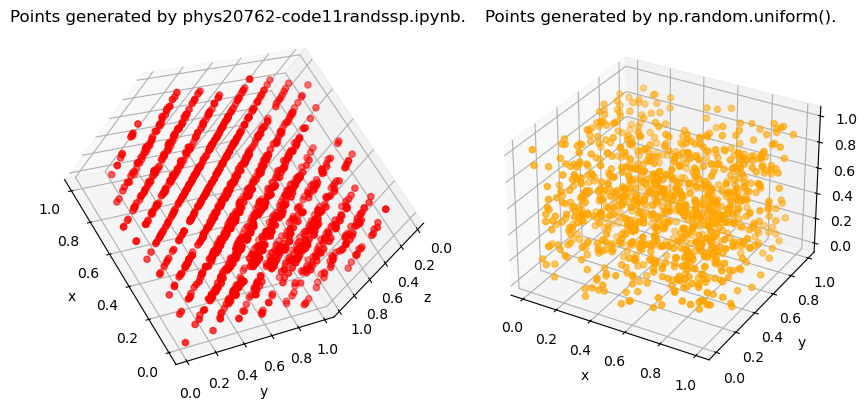

In [7]:
figure,(ax1,ax2) = plt.subplots(1,2,figsize=(10,8),subplot_kw={"projection":"3d"})

# Scatter plot for points generated by phys20762-code11randssp.ipynb.
ax1.scatter(k[0, :], k[1, :], k[2, :], color="r")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
ax1.set_title("Points generated by phys20762-code11randssp.ipynb.")
ax1.view_init(elev=-40, azim=-116, roll=140)  # Set viewing angle for ax1.

# Scatter plot for points generated by np.random.uniform().
ax2.scatter(x, y, z, color="orange")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")
ax2.set_title("Points generated by np.random.uniform().")

plt.show()

From this we can see spectral lines are generated by phys20762-code11randssp.ipynb and not by ```np.random.uniform()```. Providing evidence to support ```np.random.uniform()``` reliability.

## Random numbers distributed exponentially.

Below is a random number generator that produces samples distributed according to an exponential function $\exp({-\frac{x}{\lambda}})$, where $\lambda$ is the mean free path. This will be highly important when generating the step lengths of neutron scattering in section 3 and 4.

Using the $PDF(x) = \exp({-\frac{x}{\lambda}})$ we can find the inverse CDF to get a random distribution according to the original PDF.

$PDF(x) = \exp({-\frac{x}{\lambda}})$

$CDF(x) = \lambda(1 - \exp({-\frac{x}{\lambda}}))$

$CDF^{-1}(x) = -\lambda\ln({1 - \frac{x}{\lambda}})$

If the $x$ is a random number $u_i$, then the whole log natural argument will be a random number.

$CDF^{-1}(x) = -\lambda\ln(u_i)$

This inverse CDF will give us a random distribution with the behaviour of our initial PDF, as shown below.

$s_i = -\lambda\ln(u_i)$

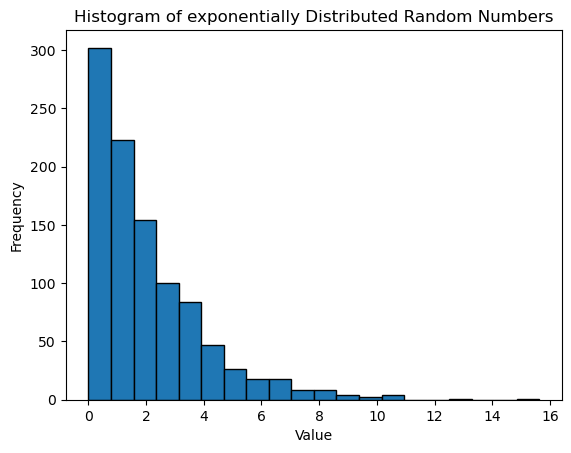

In [8]:
# Defining the number of randomally exponentially distributed points. 
no_points = 1000

mean_free_path = 2

u = np.random.uniform(0, 1, no_points)

# Using the inverse CDF from the markdown to generate random numbers distributed exponentially.b 
s = -(mean_free_path) * np.log(u)

# Plot this array of random numbers to see if it is an exponential distribution. 
plt.hist(s, bins=20, edgecolor='black')
plt.title('Histogram of exponentially Distributed Random Numbers')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

This plot is clearly reminiscent of an exponential distribution. Suggesting our method described in the markdown is valid.

In [9]:
# Putting this as a function and changing mean_free_path to lambda_ 

def random_exp_dist(N, lambda_):
    """
    N is the number of points to be randomly distributed exponentially.
    lambda_ is the mean free path length (lambda), as shown in the above markdown.

    The functions returns an array of random numbers exponentially distributed according to the mean free path length. 
    """
    # Equations used from the above markdown.
    u = np.random.uniform(0, 1, N)

    s = -(lambda_) * np.log(u)

    return s

Using this generator, we will demonstrate in the absence of scattering, the characteristic attenuation length for water is about 45 cm.
We will perform a properly weighted linear fit using ```np.polyfit``` on the data to obtain the attenuation length and its expected uncertainty.

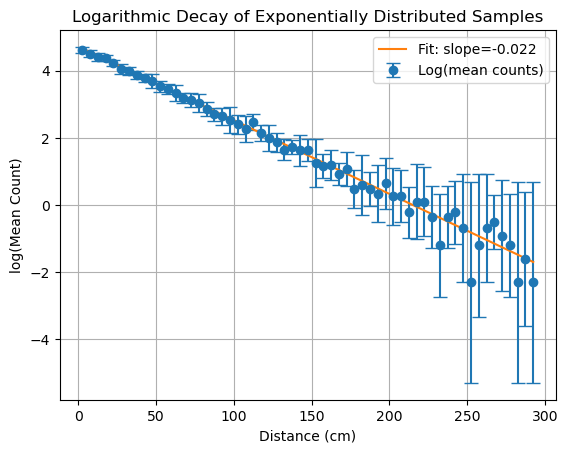

Estimated lambda from fit: 45.60 +/- 0.48 cm


In [10]:
# Parameters.
N = 1000  # Number of samples per histogram.
lambda_true = 45.0  # True mean free path length (of water) in cm.
num_histograms = 10  # Number of histograms.
bins = np.linspace(0, 300, 61)  # Bin positions and sizes (e.g. 60 bins over 0-300 cm).

# Generating histograms.
# For each histogram, collecting frequencies of each bin.
hist_counts = []

for i in range(num_histograms):
    samples = random_exp_dist(N, lambda_true)
    hist, _ = np.histogram(samples, bins=bins)
    hist_counts.append(hist) # Collecting each histogram's data into a list.

hist_counts = np.array(hist_counts) # Converting the list into an array.

# Computing the mean and standard deviation for each bin.
mean_counts = np.mean(hist_counts, axis=0)
std_counts = np.std(hist_counts, axis=0)

# Bin centers for plotting.
bin_centers = 0.5 * (bins[:-1] + bins[1:])

# Use std dev for error and remove zero counts to avoid log(0).
valid_counts = mean_counts > 0
log_counts = np.log(mean_counts[valid_counts])
log_bin_centers = bin_centers[valid_counts]
errors = std_counts[valid_counts] / mean_counts[valid_counts]  # Propagated relative error in log scale.

# Perform weighted linear fit to log data.
# Using 1/errors^2 as weights.
weights = 1 / (errors**2)
coefficients, cov_matrix = np.polyfit(log_bin_centers, log_counts, 1, w=weights, cov=True)
slope, intercept = coefficients
err_slope = np.sqrt(cov_matrix[0, 0])
lambda_estimated = -1 / slope
err_lambda_estimated = err_slope / (slope)**2

# Plot the log graph.
plt.figure()
#plt.plot(log_bin_centers, log_counts, 'o', label='Log(mean counts)') #
plt.errorbar(log_bin_centers, log_counts, yerr=errors, fmt='o', label='Log(mean counts)', capsize=5)
plt.plot(log_bin_centers, slope * log_bin_centers + intercept, '-', label=f'Fit: slope={slope:.3f}')
plt.xlabel('Distance (cm)')
plt.ylabel('log(Mean Count)')
plt.title('Logarithmic Decay of Exponentially Distributed Samples')
plt.legend()
plt.grid(True)
plt.show()

print(f"Estimated lambda from fit: {lambda_estimated:.2f} +/- {err_lambda_estimated:.2f} cm")

From this we can see that our random exponential distribution returns an appropiate mean free path length for what we gave it, however not always consistent with 45 cm.

Note: if the errorbars are too intrusive to the plot you may comment ```plt.errorbar``` and uncomment ```plt.plot```.

In section 3.2 it is useful to be able to generate just one value from this distribution.

In [11]:
# Putting this as a function to just return one value. To be used as a step length.

def random_exp_single(lambda_):
    """
    lambda_ is the mean free path length (lambda), as shown in the above markdown.

    The functions returns a single random number exponentially distributed according to the mean free path length. 
    """
    # Equations used from the above markdown.
    u = np.random.uniform(0, 1)

    s = -(lambda_) * np.log(u)

    return s

## Isotropic unit vectors.

Below we will write a function that produces isotropic unit vectors $\vec{r} = x\hat{i} + y\hat{j} + z\hat{k}$  such that  $|\vec{r}| = 1$.

This will be highly important when generating the isotropic directions of neutron scattering in section 3 and 4.

We'll use spherical polar first and then convert to cartesian coordinates.

$x = |r|\sin{\theta}\cos{\phi}$

$y = |r|\sin{\theta}\sin{\phi}$

$z = |r|\cos{\theta}$

In [12]:
# Isotropic unit vectors generator
def isotropic_unit_vectors(N):
    """
    N is the number of isotropic unit vectors to be generated.

    This function generates N isotropic unit vectors.
    """
    # Initially in spherical polar.
    phi = np.random.uniform(0, 2 * np.pi, N)
    cos_theta = np.random.uniform(-1, 1, N)
    theta = np.arccos(cos_theta)

    # Convert to cartesian coordinates.
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = cos_theta
    
    return np.column_stack((x,y,z))

As we model the slab as infinitely wide in the $y$ and $z$ directions it becomes optimal to only track the x position. Below is a function to only generate the isotropic $x$ direction.

In [13]:
def isotropic_x_direction(N):
    """
    N is the number of isotropic unit vectors (for x) to be generated.

    This function generates N isotropic unit vector components for x.
    """
    # Initially in spherical polar.
    phi = np.random.uniform(0, 2 * np.pi, N)
    cos_theta = np.random.uniform(-1, 1, N)
    theta = np.arccos(cos_theta)

    # Convert to cartesian coordinates.
    x = np.sin(theta) * np.cos(phi)

    return x

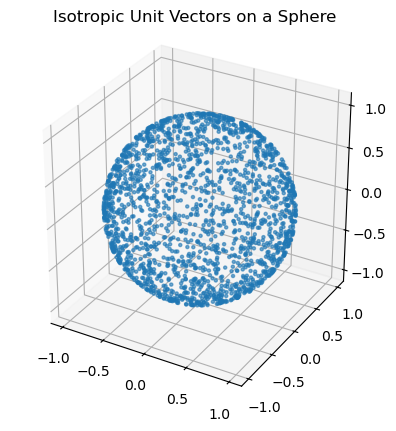

In [14]:
# Visualise with interactive scatter plot
r_unit = isotropic_unit_vectors(2000)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(r_unit[:, 0], r_unit[:, 1], r_unit[:, 2], alpha=0.6, s=5)
ax.set_title("Isotropic Unit Vectors on a Sphere")
ax.set_box_aspect([1,1,1])
plt.show()

We can see from this plot that the points are uniformly distributed over the sphere which suggests reliability of our function ```isotropic_unit_vectors()```.

This plot shows that the points are uniformly distributed over the sphere, indicating that our function ```isotropic_unit_vectors()``` works correctly.

Again for 3.2 , it will be useful to have this return just one direction.

In [15]:
# Isotropic unit vector generator
def isotropic_unit_vector_single():
    """
    This function generates only one isotropic unit vectors.
    """
    # Initially in spherical polar.
    phi = np.random.uniform(0, 2 * np.pi)
    cos_theta = np.random.uniform(-1, 1)
    theta = np.arccos(cos_theta)

    # Convert to cartesian coordinates.
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = cos_theta
    
    return np.array([x , y , z])

## Isotropic steps with lengths distributed as exp($\frac{x}{\lambda}$).

From section 2.3 we have a function that generates isotropic unit vectors, which will generate the directions for our steps.

We can also generate a step length distributed exponentially, from the inverse CDF as shown in 2.2.

The combination of these will be used to model neutron scattering in section 3 and 4.

In [16]:
def isotropic_steps(N, lambda_):
    """
    N is the number of points to be randomly distributed exponentially.
    lambda_ is the mean free path length (lambda).

    The functions uses the functions isotropic_unit_vectors & random_exp_dist to generate:
    vectors of random direction with lengths distributed exponentially.
    """

    r_unit = isotropic_unit_vectors(N)

    step_length = random_exp_dist(N, lambda_)

    r_step = step_length[:, np.newaxis] * r_unit # Each of exponentially dist lengths mutltiply one of the directions.

    return r_step

In [17]:
def isotropic_step_single(lambda_):
    """
    lambda_ is the mean free path length (lambda).

    The functions uses the functions isotropic_unit_vector & random_exp_dist to generate:
    a single vector of random direction with it's length distributed exponentially.
    """

    r_unit = isotropic_unit_vector_single()

    step_length = random_exp_single(lambda_)

    r_step = step_length * r_unit

    return r_step

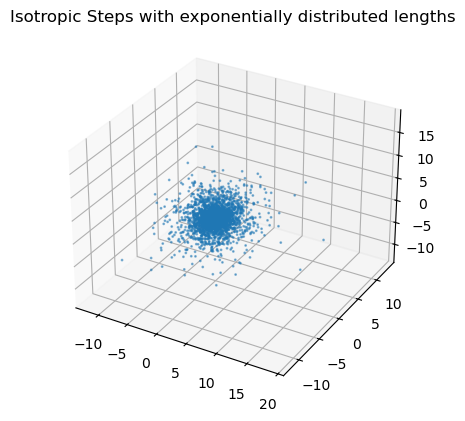

In [18]:
# Extracting 5000 vectors of random direction and with lengths distributed exponentially.
isotropic_step_1 = isotropic_steps(5000, 2)

# Plotting these points.
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(isotropic_step_1[:, 0], isotropic_step_1[:, 1], isotropic_step_1[:, 2], s=1, alpha=0.5)
ax.set_title("Isotropic Steps with exponentially distributed lengths")
plt.show()

This plot shows that ```isotropic_steps()``` produces exponentially distributed step lengths with isotropic directions.

# Behaviour of Neutrons.

In this section we use the methods shown in section 2 to simulate neutrons travelling through shielding material. We visualise the paths of these neutrons and calculate their absorption, reflection and transmission rates. We investigate how these rates differ depending on the thickness of the material, from which we find the characteristic attenuation lengths of water, lead and graphite.

## Determining Material Properties.

Using Table 1 from the brief, below I will state the properties of Water, Lead and Graphite.

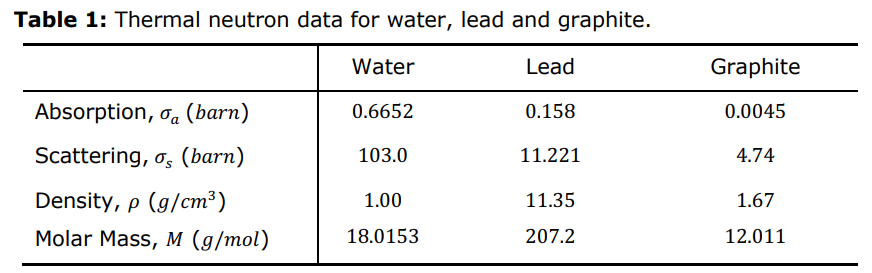

In [19]:
# Stating the properties. The indices 0, 1 & 2 are Water, Lead & Graphite respectively.

sigma_a = np.array([0.6652, 0.158, 0.0045]) # Absorption cross section. Units: barn.

sigma_s = np.array([103.0, 11.221, 4.74]) # Scattering  cross section. Units: barn.

density = np.array([1.00, 11.35, 1.67]) # Units: g/cm^3.

molar_mass = np.array([18.0153, 207.2, 12.011]) # Units: g/mol.

I will use this properties to calculate the macroscopic absorption, scattering cross-sections and the total mean free path length $\lambda$, for all materials.

The equations below will be used.

$n = \frac{\rho N_A}{M}$, where $n$ is the number of absorbing molecules per unit volume and $N_A$ is Avogrados constant.

$\Sigma_j = n \sigma_j$, where $\Sigma_j$ is the macroscopic cross section and $\sigma_j$ is the microscopic cross section (j = a or s).

The total macroscopic cross section $\Sigma_T = \Sigma_a + \Sigma_s$.

The mean free path length $\lambda_T = \frac{1}{\Sigma_T}$.

In [20]:
# Defining Avogrado's constant.
avogrado = 6.022 * 10**(23)

n = (density * avogrado) / molar_mass

# Defining the macroscopic absorption cross section.
macro_a = n * (sigma_a * 10**(-24)) # Converting from barn to cm^2.

# Defining the macroscopic scattering cross section.
macro_s = n * (sigma_s * 10**(-24)) # Converting from barn to cm^2.

# Defining the total macroscopic cross section.
macro_T = macro_a + macro_s

# Defining the mean free path length, lambda_T.
lambda_T_array = 1 / (macro_T)

The absorption probability is: $P_a = \frac{\Sigma_a}{\Sigma_a + \Sigma_s}$

In [21]:
# Finding the absorption probabilities of the materials.
abs_probs_array = macro_a / macro_T

## Visualising Neutron Random Walk.

As the breif states, we will now visualise the random walk of a few neutrons through each material.

We will consider a slab of thickness $L$ placed between $x=0$ & $x=L$. 

Each neutron will enter perpendicularly from $x=0$ and then perform a random walk using step lengths from the exponential distribution $\exp(\frac{-x_i}{\lambda})$, where $x_i$ is the $x$ coordinate of the neutron at step $i$.

At each step the neutron will be absorbed, escape or scattered within the slab and continue it's random walk.

Below a few paths will be added to a list for each material. So that we can plot the paths below.

In [22]:
def simulate_neutron_rand_walk(L, lambda_, abs_prob):
    """
    L is the length of the slab in cm, as described in the markdown above.
    lambda_ is the mean free path length (lambda) of one of the materials, in cm. Taken from lambda_T_array.
    abs_prob is the absorption probability of one of the materials. Taken from the array abs_probs_array.

    This function simulates a neutron random walk in a slab of length L, as described in the markdown above.
    It uses a while loop to continue scattering within the slab unless the neutron is absorbed or escapes.
    Once the walk (while loop) is over it returns the status of the neutron, whether it was:
    absorbed, reflected or transmitted.
    """
    pos = np.array([0.0, 0.0, 0.0])
    direction = np.array([1.0, 0.0, 0.0]) # Initially entering the slab in the x direction.
    path = [pos.copy()]
    
    while 0 <= pos[0] <= L:
        step_length = random_exp_single(lambda_)
        #direction = isotropic_unit_vector_single()
        # The above code would overwrite the inital direction. 
        # The change in direction will occur at the end of the while loop, if no escape or absorption.
        pos = pos + step_length * direction
        path.append(pos.copy())
        
        # Check if escaped.
        if pos[0] < 0:
            return "Reflected", np.array(path)
        elif pos[0] > L:
            return "Transmitted", np.array(path)
        
        # Then check if absorbed as we are still within the slab.
        if np.random.uniform(0, 1) < abs_prob:
            return "Absorbed", np.array(path)
        
        # If neither of these then the while loop continues. The neutron is scattered in the slab again.
        # Until one of these conditions are met.
        # Direction of next scatter is below.
        direction = isotropic_unit_vector_single()

Note: the function ```simulate_neutron_rand_walk``` is not efficient over many iterations due to the use of ```if``` statements. As seen later improvements are made to optimise this process.

In [23]:
# Choosing a certain L (slab width).
slab_width_few = 10 # Named slab_width_few as it is only for simulating a few neutrons.

# Defining empty path lists for each material.
water_paths = []
lead_paths = []
graphite_paths = []

# Using the for loop below the path lists for each material.

# Number of neutrons to simulate for each material.
num_neutrons = 3

for i in range(num_neutrons):
    # For lambda_array & abs_prob_array the indices used are for the corresponding material.
    # 0 : water, 1 : lead & 2 : graphite.
    
    water_paths.append(simulate_neutron_rand_walk(slab_width_few, lambda_T_array[0], abs_probs_array[0]))
    lead_paths.append(simulate_neutron_rand_walk(slab_width_few, lambda_T_array[1], abs_probs_array[1]))
    graphite_paths.append(simulate_neutron_rand_walk(slab_width_few, lambda_T_array[2], abs_probs_array[2]))

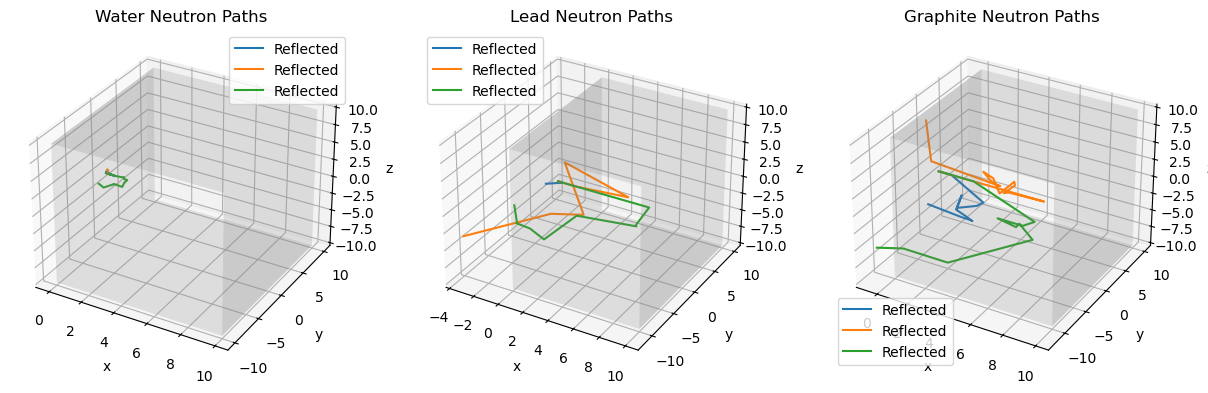

In [24]:
# We will plot the paths of each material on a seperate subplot.
fig = plt.figure(figsize=(15, 5))

# Creating a semi transparent region to represent the slab.
def draw_slab(ax, L, ylims=(-10, 10), zlims=(-10, 10)):
    y0, y1 = ylims
    z0, z1 = zlims
    slab_faces = [
        [[0, y0, z0], [L, y0, z0], [L, y1, z0], [0, y1, z0]],  # bottom.
        [[0, y0, z1], [L, y0, z1], [L, y1, z1], [0, y1, z1]],  # top.
        [[0, y0, z0], [0, y1, z0], [0, y1, z1], [0, y0, z1]],  # x = 0.
        [[L, y0, z0], [L, y1, z0], [L, y1, z1], [L, y0, z1]]   # x = L.
    ]
    slab = Poly3DCollection(slab_faces, alpha=0.2, facecolors="gray")
    ax.add_collection3d(slab)


# Water subplot.
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
for status, path in water_paths:
    ax1.plot(path[:,0], path[:,1], path[:,2], label=status)
ax1.set_title("Water Neutron Paths")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
# To include the slab boundaries.
draw_slab(ax1, slab_width_few)
ax1.legend()

# Lead subplot.
ax2 = fig.add_subplot(1, 3, 2, projection="3d")
for status, path in lead_paths:
    ax2.plot(path[:,0], path[:,1], path[:,2], label=status)
ax2.set_title("Lead Neutron Paths")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")
draw_slab(ax2, slab_width_few)
ax2.legend()

# Graphite subplot.
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
for status, path in graphite_paths:
    ax3.plot(path[:,0], path[:,1], path[:,2], label=status)
ax3.set_title("Graphite Neutron Paths")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_zlabel("z")
draw_slab(ax3, slab_width_few)
ax3.legend()

Visualising the random walks for each material above. Each time we re-simulate the random walks we can see quite a lot of variation for each materials. However clearly water's step lengths are much smaller, suggesting a smaller characteristic attenuation length. 

## Quantifying Scattering Processes.

As discussed in the brief, we will set $L = 10$cm and repeat the previous process without visualising random walks.

Simulating $N$ neutrons to determine the fraction of absorption $(\frac{N_A}{N})$, reflection $(\frac{N_R}{N})$ and transmission $(\frac{N_T}{N})$ which are called rates. This can be done having measured $N_A$, $N_R$ & $N_T$.

We will calculate the uncertainty associated with each process. $N_A$, $N_R$ & $N_T$ are tallies, running the whole simulation many times (e.g ten iterations) we can find the mean and standard deviation of these tallies. Using the standard deviation as the error.

In [25]:
def n_iterations_rates(n_iterations, N, L, lambda_, abs_prob):
    """
    n_iterations is the number of iterations (simulations) used to calculate the mean and std of these tallies.
    N is the number of neutrons to be simulated, in each iteration.
    L is the length of the slab in cm, as described in the markdown above.
    lambda_ is the mean free path length (lambda) of one of the materials. Taken from lambda_T_array.
    abs_prob is the absorption probability of one of the materials. Taken from the array abs_probs_array.

    This function runs multiple iterations (simulations).
    Using these multiple tallies to find the mean and standard devation of the:
    reflection, transmission and absorption rates.
    Specific to a certain material and slab width, defined using L, lambda_ and abs_prob.
    It returns rates stats, which contains the mean and std for each rate.
    """

    # Defining for each status, with each index a tally for its corresponding iteration.
    n_reflected = np.zeros(n_iterations)
    n_transmitted = np.zeros(n_iterations)
    n_absorbed = np.zeros(n_iterations)
    
    # Loop over n_iterations.
    #for i in tnrange(n_iterations, desc="Progress"):
    for i in range(n_iterations):
        
        x = random_exp_dist(N, lambda_) # Initially entering the slab in the x direction at x = 0.
        
        while len(x) > 0: # While there are still particles in the slab.

            # n_status[i] is the tally for this iteration.
            # np.count.nonzero() 
            n_reflected[i] += np.count_nonzero(x < 0) # Adding the number of particles reflected to n_reflected[i]. 
            n_transmitted[i] += np.count_nonzero(x > L) # Adding the number of particles transmitted to n_transmitted[i]. 
            u = np.random.uniform(0, 1, len(x))  # Determining which indices are absorbed.
            n_absorbed[i] += np.count_nonzero(u[np.argwhere((x > 0) & (x < L))] < abs_prob) # Adding the number of particles absorbed to n_absorbed[i].

            x = np.delete(x, np.argwhere((x < 0) | (x > L) | (u < abs_prob)))

            direction = isotropic_x_direction(len(x)) # Defining isotropic x direction for next step.
            x = x + (random_exp_dist(len(x), lambda_) * direction) # All neutrons remaining are scattered again.

    # Calculating mean rates.
    mean_reflected_rate = np.mean(n_reflected) / N
    mean_transmitted_rate = np.mean(n_transmitted) / N
    mean_absorbed_rate = np.mean(n_absorbed) / N

    # Calculating std rates.
    std_reflected_rate = np.std(n_reflected) / N
    std_transmitted_rate = np.std(n_transmitted) / N
    std_absorbed_rate = np.std(n_absorbed) / N

    # Defining a dictionary that includes the mean and std rate for each status.
    rates_stats = {"Reflected" : [mean_reflected_rate, std_reflected_rate],
                  "Transmitted": [mean_transmitted_rate, std_transmitted_rate],
                  "Absorbed": [mean_absorbed_rate, std_absorbed_rate]}

    return rates_stats

The function ```n_iterations_rates``` is higly efficient due to the lack of ```if``` statements in the while loop. It also only tracks the $x$ position which is possible due to our model of the slab being infinitely wide in $y$ and $z$ directions.

Functions for displaying these results are below.

In [26]:
# Function was intially used but replaced with the use of pie charts.
def print_rates(material_name, rates_stats):
    """
    material_name is the name of the material corresponding to the rates_stats argument.
    rates_stats are the stats of a specific material to be printed.

    Using the rates_stats from the cell above, this function prints the mean and its std.
    For a single material.
    """
    print(f"--- {material_name} ---")
    for status, (mean, std) in rates_stats.items():
        print(f"{status:<12}: {mean:.4f} ± {(std / mean):.4f}") # For normalised error.

In [27]:
def plot_rates_pie_chart(title, rates_stats):
    """
    title is a string used to describe the scenario, the materials and their respective lengths.
    rates_stats are the stats of a specific scenario to be plotted as a pie chart.

    This function plots the mean rates as a pie chart for a single scenario.
    It also prints the same output as print_rates
    """
    print(f"--- {title} ---")
    
    # Prepare data for the pie chart
    labels = []
    sizes = []
    errors = []

    for status, (mean, std) in rates_stats.items():
        labels.append(f"{status} ({mean*100:.1f}%)")
        sizes.append(mean)
        errors.append(std / mean)  # Normalized error
        print(f"{status:<12}: {mean:.4f} ± {(std / mean):.4f}") # For normalized error.
    
    # Plot the pie chart
    plt.figure(figsize=(6, 6))
    plt.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=140, 
            colors=["lightcoral", "skyblue", "lightgreen"])
    plt.show()

In [28]:
def plot_three_pie_charts(titles, rates_stats_list):
    """
    titles is a list of strings used to describe the scenario, the materials and their respective lengths.
    rates_stats_list is the stats of a specific scenario to be plotted as a pie chart.
    
    Plots three pie charts for neutron interaction rates for three different scenarios.
    It also prints the same output as print_rates.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    for i, (titles, rates_stats) in enumerate(zip(titles, rates_stats_list)):
        # Prepare data for the pie chart.
        labels = []
        sizes = []
        text_output = []

        for status, (mean, std) in rates_stats.items():
            labels.append(f"{status}")
            sizes.append(mean)
            text_output.append(f"{status:<12}: {mean:.4f} ± {(std / mean):.4f}") # Normalized error

        # Plot the pie chart
        axes[i].pie(sizes, labels=labels, autopct="%1.1f%%", startangle=140,
                    colors=["lightcoral", "skyblue", "lightgreen"],
                   wedgeprops={"linewidth": 3.0, "edgecolor": 'white'})
        axes[i].set_title(f"{titles}")

        # Display the textual information underneath the pie chart
        axes[i].text(0.5, -0.2, f"--- {titles} ---\n" + "\n".join(text_output),
                     ha='center', va='top', transform=axes[i].transAxes, fontsize=10)
    
    plt.tight_layout()
    plt.show()

In [29]:
# Running the siumulations for many batches for each material.
# To find the mean and its std/error for the rate values.
num_simulations = 10 # Define the number of simulations to be used.

# Within each loop/batch num_neutrons random walks will be simulated, with slab of 10cm.
num_neutrons = 10000
slab_width = 10

In [30]:
# We calculate the mean rates and their uncertainties for 10cm of water, lead and graphite. 
rates_stats_water = n_iterations_rates(num_simulations, num_neutrons, slab_width, lambda_T_array[0], abs_probs_array[0])
rates_stats_lead = n_iterations_rates(num_simulations, num_neutrons, slab_width, lambda_T_array[1], abs_probs_array[1])
rates_stats_graphite = n_iterations_rates(num_simulations, num_neutrons, slab_width, lambda_T_array[2], abs_probs_array[2])

In [31]:
# Combaining the rate statistics to put into function plot_three_pie_charts.
pie_stats_list = [rates_stats_water, rates_stats_lead, rates_stats_graphite]

# Combining the titles to put into the function plot_three_pie_charts.
pie_titles_list = ["10cm of Water", "10cm of Lead", "10cm of Graphite"]
# The plotting in this form makes it easier to comapare.

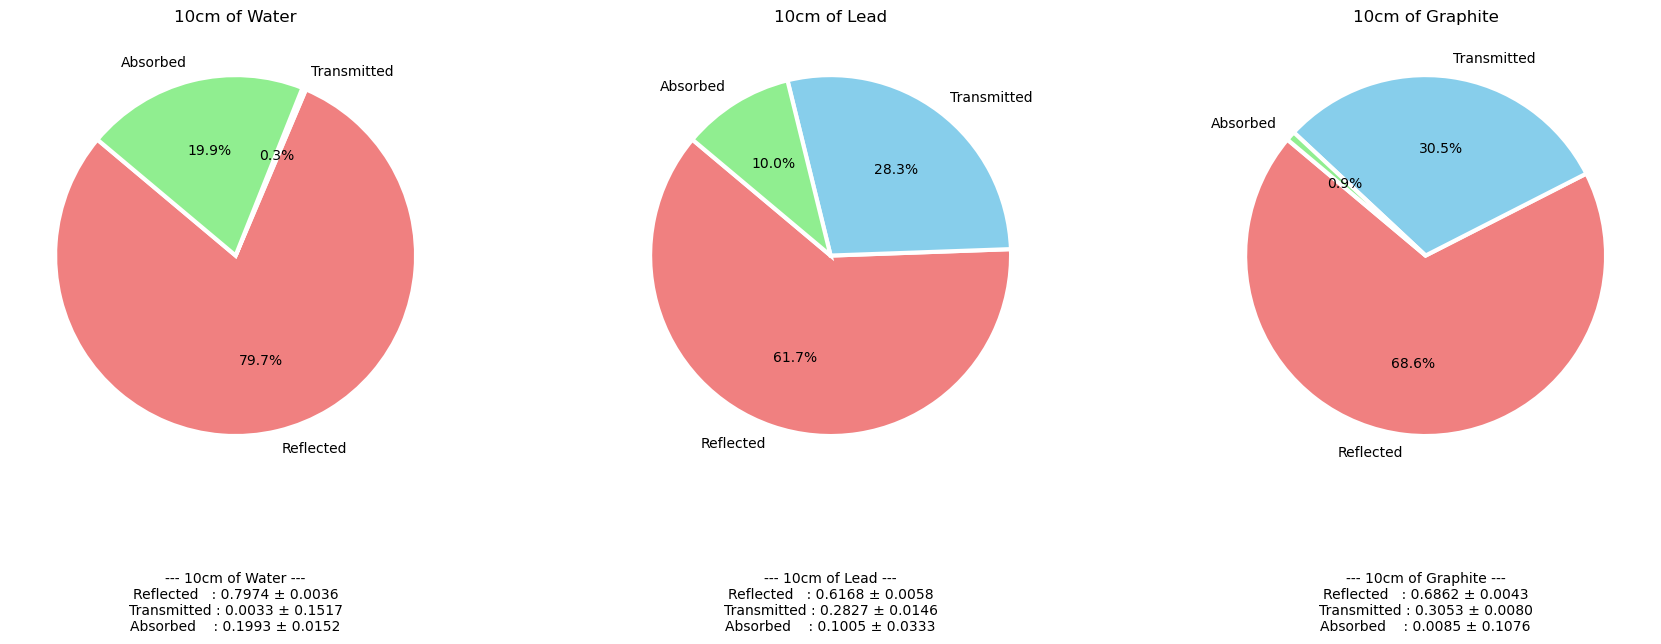

In [32]:
# Plotting the three scenarios rates with pie charts.
plot_three_pie_charts(pie_titles_list, pie_stats_list)

The pie charts above help to visualise and compare the rate statistics of water, lead and graphite.

We can see that water has a transmission rate of almost zero, which makes sense due to its mean free path being small in comparision to 10cm. Lead and graphite share higher transmission rates than that of water due to their higher mean free paths.

However water has a greater absorption rate than the others, graphite's being negligible. Again this makes sense due to graphite's very low absorption probability. Although lead possesses an absorption probability greater than water's our results still make physical sense. Lead's higher mean free path indicates particles would spend less time in the slab than water, causing a higher chance of absorption. The neutrons scattering more times in water is also clear from the plots in section 3.2 and the runtime of water being longer.

Our results making physical sense suggests that our function ```n_iterations_rates``` is valid and models the neutron transport successfully.

It also suggests that water would be the best neutron shield.

## Plotting Variations.

In section 3.4, we investigate how the thickness of the slab $L$ affects the rates. We plot the absorption, reflection and transmission rates against $L$ for all materials.

In [33]:
def rates_vs_slab_lengths(lengths, n_iterations, N, lambda_, abs_prob):
    """
    lengths is an array of slab widths that the function will iterate through.
    n_iterations is the number of iterations used to calculate the mean and std, in the function n_iterations_rates.
    N is the number of neutrons to be simulated.
    lambda_ is the mean free path length (lambda) of one of the materials, in cm. Taken from lambda_T_array.
    abs_prob is the absorption probability of one of the materials. Taken from the array abs_probs_array.
    
    Runs n_iterations_rates for a range of slab lengths returning the rates and stds.
    Finding these values we can plot how the slab length effects these rates. 
    Returns a dictionary containing lists of rate and std for each status.
    """
    # Creating an empty dictionary to contain all our rate data and their corresponding lengths.
    results = {
        "Length": [],
        "Absorbed_rate": [], "Absorbed_std": [],
        "Reflected_rate": [], "Reflected_std": [],
        "Transmitted_rate": [], "Transmitted_std": []
    }

    #for i in tnrange(len(lengths), desc="Progress"):
    for i in range(len(lengths)):
        # Runs n_iterations_rates for many lengths. Returning the data in the dictionary results.
        stats = n_iterations_rates(n_iterations, N, lengths[i], lambda_, abs_prob)

        results["Length"].append(lengths[i])
        for status in ["Absorbed", "Reflected", "Transmitted"]:
            results[f"{status}_rate"].append(stats[status][0])
            
            results[f"{status}_std"].append(stats[status][1])

    return results

In [34]:
# Defining slab widths to loop over and plot.
slab_widths_array = np.linspace(1, 20, 20)

In [35]:
# Extracting the data that shows how the rates change with slab width, for each material.
rates_vs_widths_water = rates_vs_slab_lengths(slab_widths_array, num_simulations, num_neutrons, lambda_T_array[0], abs_probs_array[0])
rates_vs_widths_lead = rates_vs_slab_lengths(slab_widths_array, num_simulations, num_neutrons, lambda_T_array[1], abs_probs_array[1])
rates_vs_widths_graphite = rates_vs_slab_lengths(slab_widths_array, num_simulations, num_neutrons, lambda_T_array[2], abs_probs_array[2])

In [36]:
def plot_rates_vs_widths(data, material_name):
    """
    data is a dictionary returned from the function rates_slab_lengths. I contains all rates for the subsequent slab widths.
    material_name is a string of what the material is called for the plot title.
    
    Plots the Absorbed, Reflected and Transmitted rates against slab length, each within its own subplot.
    Repeating with data of all three materials.
    """
    # Extracting the length data.
    slab_widths = data["Length"]
    # Plot for each status.
    statuses = ["Absorbed", "Reflected", "Transmitted"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharex=True)
    fig.suptitle(f"Neutron Rates against Slab Width in {material_name}.", fontsize=16)
    colors = ["tab:blue", "tab:orange", "tab:green"]

    for i, status in enumerate(statuses):
        axes[i].errorbar(slab_widths, data[f"{status}_rate"], yerr=data[f"{status}_std"], fmt='o-', color=colors[i], label=status)
        axes[i].set_xlabel("Slab Thickness L (cm)")
        axes[i].set_ylabel(f"{status} Rate")
        axes[i].set_title(f"{status} Rate vs Slab Thickness")
        axes[i].grid(True)
        axes[i].legend()
        #axes[i].set_ylim(0, 0.38)
    plt.tight_layout()
    plt.show()

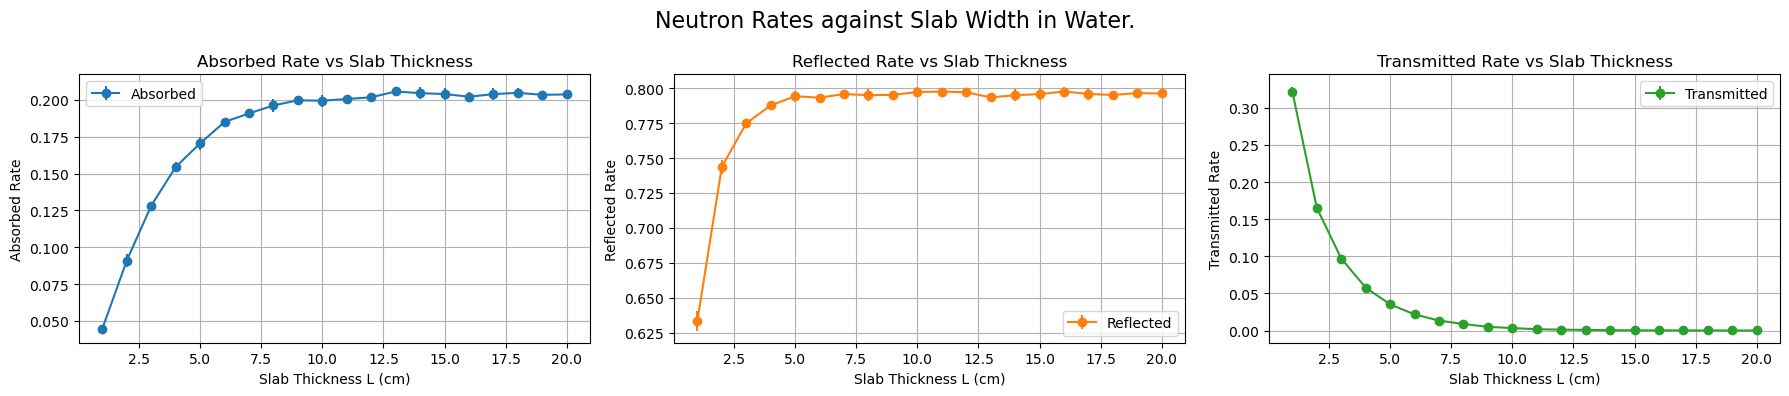

In [37]:
# Plotting neutron rates against slab width in water.
plot_rates_vs_widths(rates_vs_widths_water, "Water")

For water we can see that the absorption and reflection rates have quite a sharp increase and then plateau at 10cm and 5cm respectively. The transmission rates very quickly drop with what looks like exponential decay, tending to zero after 10cm.

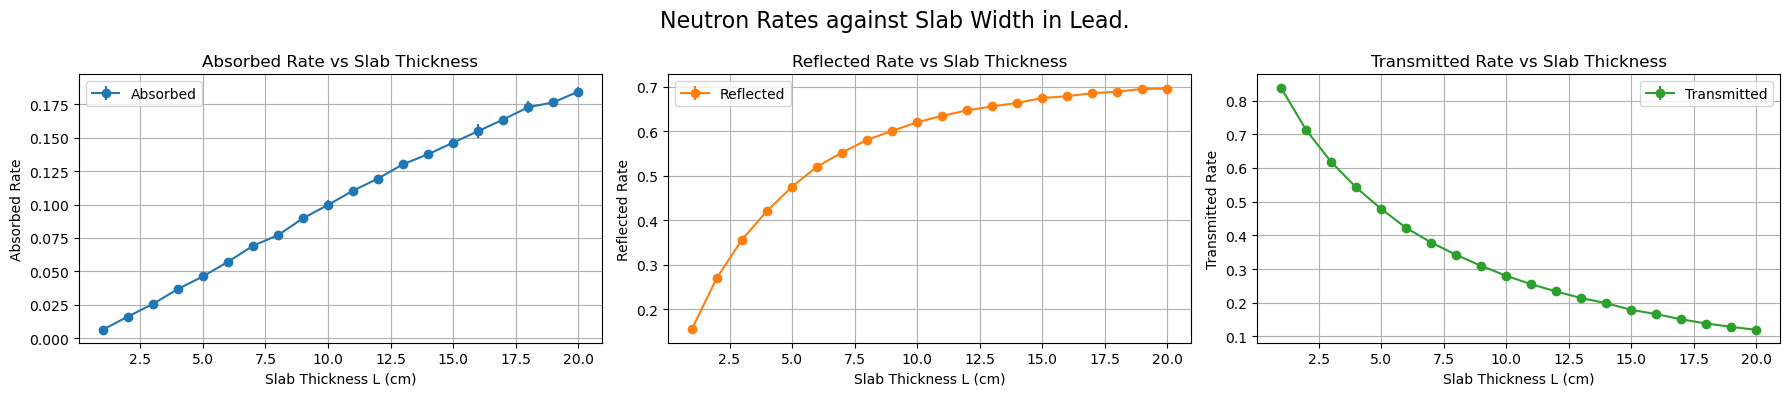

In [38]:
# Plotting neutron rates against slab width in lead.
plot_rates_vs_widths(rates_vs_widths_lead, "Lead")

For lead we can see that the absorption rate expresses an linear rate in the range of lengths we used. This makes sense as although the absorption probability does not increase, the longer the slab the more time the neutron will likely spend and the more chance of absorption.  However as seen earlier these rates are low. 

The reflection rates start low and gradually increase to 0.7 at 20cm where it looks as if it will begin to plateau. The transmission rates start high due to the mean free path length being high compared to the low slab thicknesses. The plot describes an exponential decay which will eventually tend to zero.

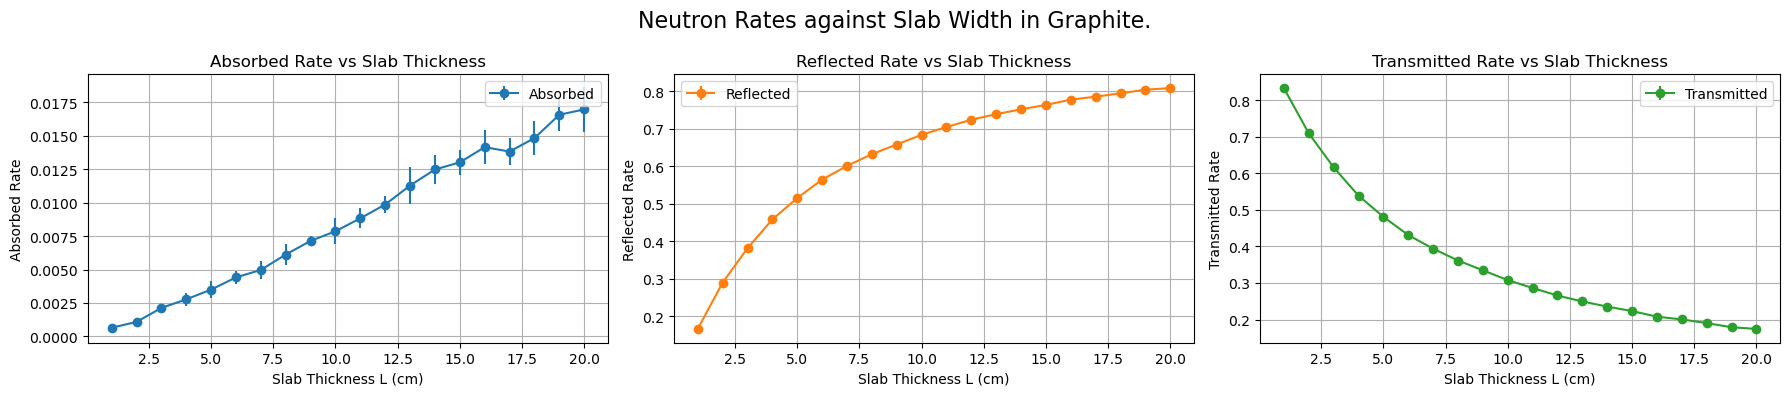

In [39]:
# Plotting neutron rates against slab width in graphite.
plot_rates_vs_widths(rates_vs_widths_graphite, "Graphite")

For graphite much is the same as lead. The main difference is absorption rate being much lower even though it also has a linear relation ship to $L$. We saw this for 10cm of graphite in 3.3 and can be explained by the much lower absorption probability. 

## Determining Attenuation Lengths.

As stated in the brief, we will calculate the characteristic attenuation lengths and the associated errors for all three materials, using their transmission rates.

Below will include a summary of the numerical data and representative graphs illustrating the results are above.

To extract the attenuation lengths, which I'll label $\lambda_{trans}$ , we will model the variation of transmission rate $T = \frac{N_T}{N}$ with the slab width $L$ exponentially, due to the likeness in the plots above.

Approximately $T(L) \propto \exp({\frac{-L}{\lambda_{trans}}})$.

Taking the logarithm we can find, $\ln(T) = -\frac{L}{\lambda_{trans}} + C$, where $C$ is a constant.

Therefore if we plot $\ln(T)$ against $L$ we can find a gradient in terms of $-\frac{1}{\lambda_{trans}}$.

In [40]:
def fit_lambda_trans_multi(data_list, material_names):
    """
    data_list is a list of dictionaries, each returned from the function rates_vs_slab_lengths.
    material_names is a list of strings representing the material names for the plot titles.
    
    Plots three graphs showing ln(T) vs L for three different materials, each with a line of best fit.
    Using the method in the above markdown to find the gradient in terms of lambda_trans.
    Displays the textual results underneath each graph.
    """

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # Create a 1x3 grid of plots.

    for i, (data, material_name) in enumerate(zip(data_list, material_names)):
        slab_widths = np.array(data["Length"])  # Extracting slab widths.
        T = np.array(data["Transmitted_rate"])  # Extracting transmission rates.
        T_std = np.array(data["Transmitted_std"])  # Extracting stds of transmission rates.

        # Filter out non-positive transmission rates to avoid log issues.
        indices = T > 0
        slab_widths = slab_widths[indices]
        T = T[indices]
        T_std = T_std[indices]
        
        # Log transformation and uncertainty propagation.
        ln_T = np.log(T)
        ln_T_std = T_std / T

        # Fitting ln(T) vs slab_widths.
        coeffs, cov = np.polyfit(slab_widths, ln_T, 1, w=(1 / ln_T_std), cov=True)
        gradient = coeffs[0]
        gradient_err = np.sqrt(cov[0][0])
        intercept = coeffs[1]
        lambda_trans = -1 / gradient
        lambda_trans_err = gradient_err / gradient**2

        # Chi-squared calculation.
        ln_T_fit = gradient * slab_widths + intercept
        residuals = ln_T - ln_T_fit
        chi_squared = np.sum((residuals / ln_T_std) ** 2)
        dof = len(slab_widths) - 2
        reduced_chi_squared = chi_squared / dof if dof > 0 else np.nan

        # Prepare textual information.
        text_output = [
            f"Characteristic attenuation length: {lambda_trans:.4f} ± {lambda_trans_err:.4f} cm",
            f"Chi-squared: {chi_squared:.2f}",
            f"Reduced chi-squared: {reduced_chi_squared:.2f}"
        ]

        # Subplot for each material.
        axes[i].errorbar(slab_widths, ln_T, yerr=ln_T_std, fmt="o", label="Data (ln T)", capsize=4)
        axes[i].plot(slab_widths, ln_T_fit, label=f"Fit: ln(T) = {gradient:.2f}x + {intercept:.2f}", color="red")
        axes[i].set_xlabel("Slab Thickness (cm)")
        axes[i].set_ylabel("ln(Transmission Rate)")
        axes[i].set_title(f"Transmission Fit: {material_name}")
        axes[i].legend()
        axes[i].grid(True)

        # Display the textual information underneath the graph
        axes[i].text(0.5, -0.25, f"--- {material_name} ---\n" + "\n".join(text_output),
                    ha="center", va="top", transform=axes[i].transAxes, fontsize=10)

    plt.tight_layout()
    plt.show()

In [41]:
# Combaining the rate statistics to put into function fit_lambda_trans_multi.
rates_vs_widths_list = [rates_vs_widths_water, rates_vs_widths_lead, rates_vs_widths_graphite]

# Combining the titles to put into the function fit_lambda_trans_multi.
material_name_list = ["Water", "Lead", "Graphite"]
# The plotting in this form makes it easier to comapare.

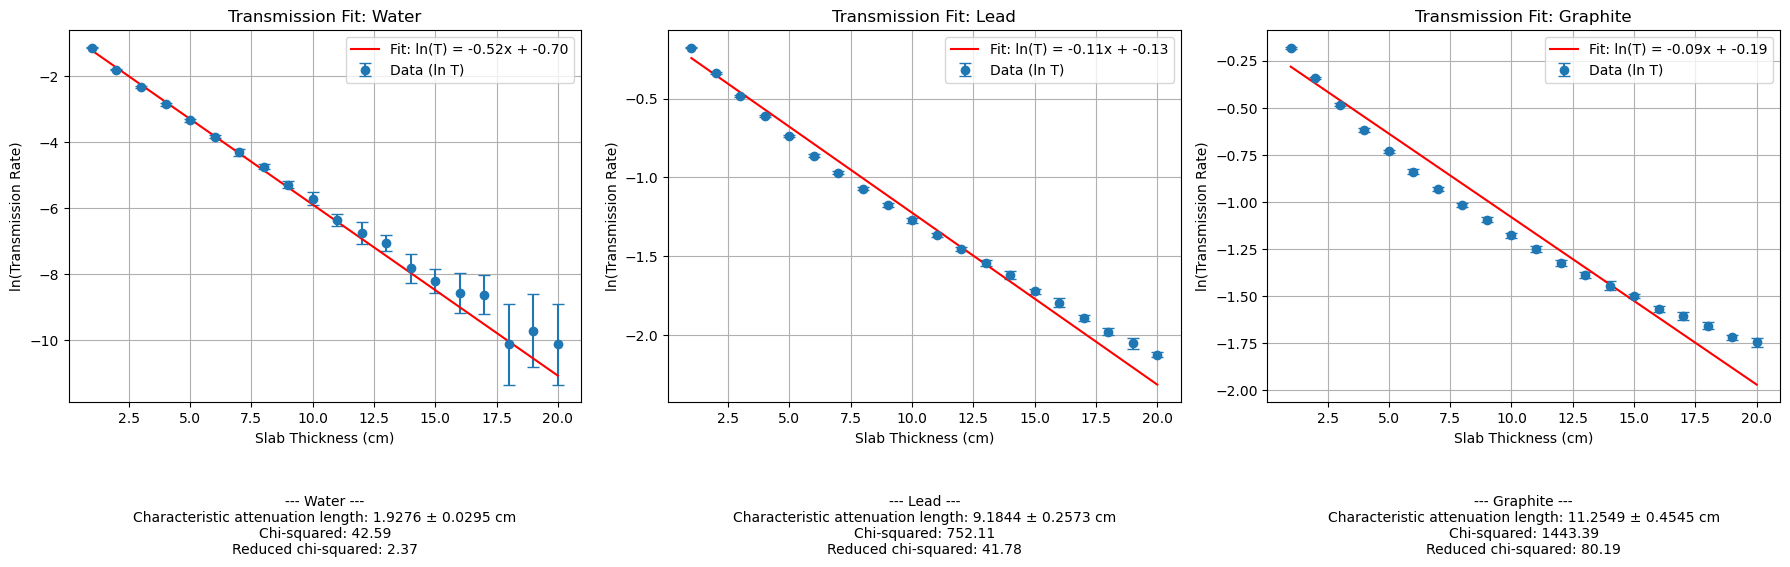

In [42]:
fit_lambda_trans_multi(rates_vs_widths_list, material_name_list)

We can see that the characteristic attenuation length of water is much lower than that of lead and graphite. 

Our reduced chi-squareds are high for lead and graphite perhaps putting our model into question. From the plot it looks like the errors are underestimated and for graphite the points don't even form a straight line.

It would be interesting to see if higher number of neutrons sent through the slab would make any difference. However this would increase the runtime.

# Stretch yourself - the Woodcock method.

As stated in the brief, I will use the woodcock method to compute the fraction of neutrons transmitted, reflected and absorbed through two adjacent slabs composed of different materials each with a thickness of 10 cm. Discussing the validation process employed to ensure the accuracy of the obtained results.



The Woodcock method works by defining one material as the fictitious region and the other as the normal. The fictitious region is the material with the larger lambda where all neutrons within have a possibility to be fictitiously or normally scattered. The neutrons scattering is decided by comparing $s > \mu$ where $s$ is a randomly generated number and $\mu = \frac{\lambda_T}{\lambda_{max}}$ is the fictitious probability. All neutrons within the normal region will be normally scattered.

Fictitious scattering is where the directions do not change and no absorption can take place. In normal scattering the directions change just as before and absorption is possible. Both step lengths are generated by a random exponential distribution like in section 3, with $\lambda = \lambda_T$ where $\lambda_T$ is the smaller lambda.

In [43]:
def woodcock_n_iterations_rates(n_iterations, N, L1, L2, lambda_1, abs_prob_1, lambda_2, abs_prob_2):
    """
    n_iterations is the number of iterations (simulations) used to calculate the mean and std of these tallies.
    N is the number of neutrons to be simulated, in each iteration.
    L1 is the length of the slab of material one in cm.
    L2 is the length of the slab of material two in cm.
    lambda_1 is the mean free path length (lambda) of material one. Taken from lambda_T_array.
    abs_prob_1 is the absorption probability material one. Taken from the array abs_probs_array.
    lambda_2 is the mean free path length (lambda) of material two. Taken from lambda_T_array.
    abs_prob_2 is the absorption probability material two. Taken from the array abs_probs_array.

    This function runs multiple iterations (simulations).
    Using these multiple tallies to find the mean and standard devation of the:
    reflection, transmission and absorption rates.
    It differs from n_iterations_rates as it uses the woodcock method to simulate two adjacent slabs.
    The specifics of the woodcock method are spoke of in the above markdown and shown below by comments.
    It returns rates stats, which contains the mean and std for each rate.
    """
    
    # Defining for each status, with each index a tally for its corresponding iteration.
    n_reflected = np.zeros(n_iterations)
    n_transmitted = np.zeros(n_iterations)
    n_absorbed = np.zeros(n_iterations)

    # Geometry boundaries.
    L_T = L1 + L2

    # Calculate maximum mean free path. Also minimum.
    max_lambda = max(lambda_1, lambda_2)
    min_lambda = min(lambda_1, lambda_2)

    # Defining the fictitious and normal region.
    if max_lambda == lambda_1:
        first_slab_fict = True
    else:
        first_slab_fict = False

    # Defining lambda_T, which is used as the mean free path for all steps.
    lambda_T = min_lambda
    
    # Defining the probability of a fictional step as shown in markdown.
    fict_prob = lambda_T / max_lambda

    # Loop over n_iterations.
    # for i in tnrange(n_iterations, desc="Progress"): # If I wished to see progress bar.
    for i in range(n_iterations):
        
        x = random_exp_dist(N, lambda_T) # Initially entering the slab in the x direction at x = 0.
        dir_x = np.ones(N) # Setting the intial direction along the x-axis, so any initial fictional steps can remain in this direction.
        
        while len(x) > 0: # While there are still particles in the slab.

            # Determining a mask for the reflected and transmitted conditions.
            reflected = (x < 0)
            transmitted = (x > L_T)
            reflected_or_transmitted = (x < 0) | (x > L_T)
            
            # Using the masks to find the number of particles reflected or scattered.
            n_reflected[i] += np.count_nonzero(reflected) # Adding the number of particles reflected to n_reflected[i].
            n_transmitted[i] += np.count_nonzero(transmitted) # Adding the number of particles transmitted to n_transmitted[i].

            # Removing any particles which are reflected or transmitted.
            x = x[~reflected_or_transmitted]
            dir_x = dir_x[~reflected_or_transmitted]

            # Generating the random number array s which is to be compared to the fict_prob.
            # The line of code below returns: 0 for particles in the normal region and a random number for neutrons in the fictitious region.
            s = np.where((x < L1) != (first_slab_fict), 0, np.random.uniform(0, 1, size=x.shape)) 

            # The neutrons with an s value greater than the fict_prob are fictitious.
            # The neutrons in the fictitious region with an s value lower than fict_prob will be scattered normally.
            # From the code above, all neutrons in the normal region have s = 0, so they will never be considered fictitious.
            is_fict = np.where(s > fict_prob, True, False)

            # Absorption of normal neutrons.
            abs_prob_all = np.where((x < L1), abs_prob_1, abs_prob_2) # Defining absorption probabilities for all neutrons, depending on the region they are in.

            abs_prob_norm = np.where(is_fict == False, abs_prob_all, 0) # Only keeping absorption probabilities for normal neutrons, as fictitious neutrons cannot be absorbed. 

            u_abs = np.random.uniform(0, 1, size=x.shape) # Generating random numbers to be compared to abs_prob_norm. 
            
            absorbed = np.where(u_abs < abs_prob_norm, True, False) # Defines a mask of absorbed neutrons. 

            n_absorbed[i] += np.count_nonzero(absorbed) # Adding the number of neutrons absorbed to n_absorbed[i].

            # Removing any neutrons absorbed.
            x = x[~absorbed]
            dir_x = dir_x[~absorbed]
            is_fict = is_fict[~absorbed] # Although no fictional neutrons are absorbed, is_fict keeps track of all neutrons. 
            # In is_fict False entries represent normally scattered particles. Therefore these elements need to be deleted to maintain the same shape as x and dir_x.

            # Defining step length using an exponential distribution using lambda_T as stated in the above markdown.
            step_length = random_exp_dist(len(x), lambda_T)

            # Defining the new directions for the next loop. For fictional neutrons the step direction is the same as the previous, for normal neutrons they get a new random isotropic direction.
            dir_x = np.where(is_fict == True, dir_x, isotropic_x_direction(len(x)))

            # Applying the step to the x array.
            x += step_length * dir_x

    # Calculating mean rates.
    mean_reflected_rate = np.mean(n_reflected) / N
    mean_transmitted_rate = np.mean(n_transmitted) / N
    mean_absorbed_rate = np.mean(n_absorbed) / N

    # Calculating std rates.
    std_reflected_rate = np.std(n_reflected) / N
    std_transmitted_rate = np.std(n_transmitted) / N
    std_absorbed_rate = np.std(n_absorbed) / N

    # Defining a dictionary that includes the mean and std rate for each status.
    rates_stats = {"Reflected" : [mean_reflected_rate, std_reflected_rate],
                  "Transmitted": [mean_transmitted_rate, std_transmitted_rate],
                  "Absorbed": [mean_absorbed_rate, std_absorbed_rate]}

    return rates_stats

One method of validation is to use two 5cm slabs of the same material, this should output the same results that 10cm of that material returned in section 3.3.

In [44]:
rates_stats_two_water = woodcock_n_iterations_rates(num_simulations, num_neutrons, 5, 5, lambda_T_array[0], abs_probs_array[0], lambda_T_array[0], abs_probs_array[0])

--- Two 5cm water slabs ---
Reflected   : 0.7957 ± 0.0052
Transmitted : 0.0032 ± 0.1160
Absorbed    : 0.2012 ± 0.0204


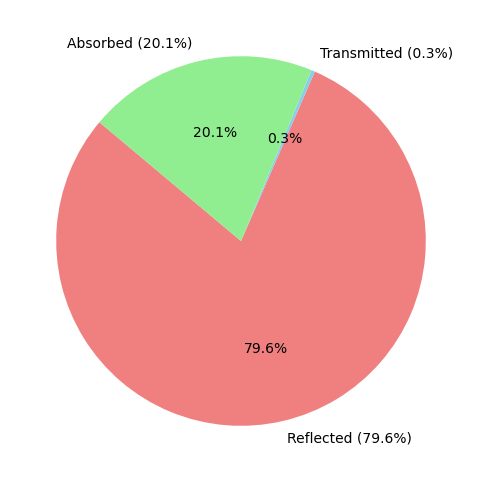

In [45]:
plot_rates_pie_chart("Two 5cm water slabs", rates_stats_two_water)

Above we have calculated the rates for two 5cm slabs using the woodcock method. The results are consistent with the 10cm slab found in section 3.3. This gives us confidence in the Woodcock method and the ```woodcock_n_iterations_rates``` function.

I will now compare the rates of two adjacent slabs of different materials.

In [46]:
# Calculating the rates for 10cm - 10cm for graphite-water, lead-water and graphite-lead in order to compare results.
rates_stats_graphite_water_10_10 = woodcock_n_iterations_rates(num_simulations, num_neutrons, 10, 10, lambda_T_array[2], abs_probs_array[2], lambda_T_array[0], abs_probs_array[0])
rates_stats_lead_water_10_10 = woodcock_n_iterations_rates(num_simulations, num_neutrons, 10, 10, lambda_T_array[1], abs_probs_array[1], lambda_T_array[0], abs_probs_array[0])
rates_stats_graphite_lead_10_10 = woodcock_n_iterations_rates(num_simulations, num_neutrons, 10, 10, lambda_T_array[2], abs_probs_array[2], lambda_T_array[1], abs_probs_array[1])

In [47]:
# Combining the rate statistics to put into function plot_three_pie_charts.
two_slabs_stats_list = [rates_stats_graphite_water_10_10, rates_stats_lead_water_10_10, rates_stats_graphite_lead_10_10]

# Combining the titles to put into the function plot_three_pie_charts.
two_slabs_titles_list = ["10cm of Graphite - 10cm of Water",
                         "10cm of Lead - 10cm of Water",
                        "10cm of Graphite - 10cm of Lead"]
# The plotting in this form makes it easier to comapare.

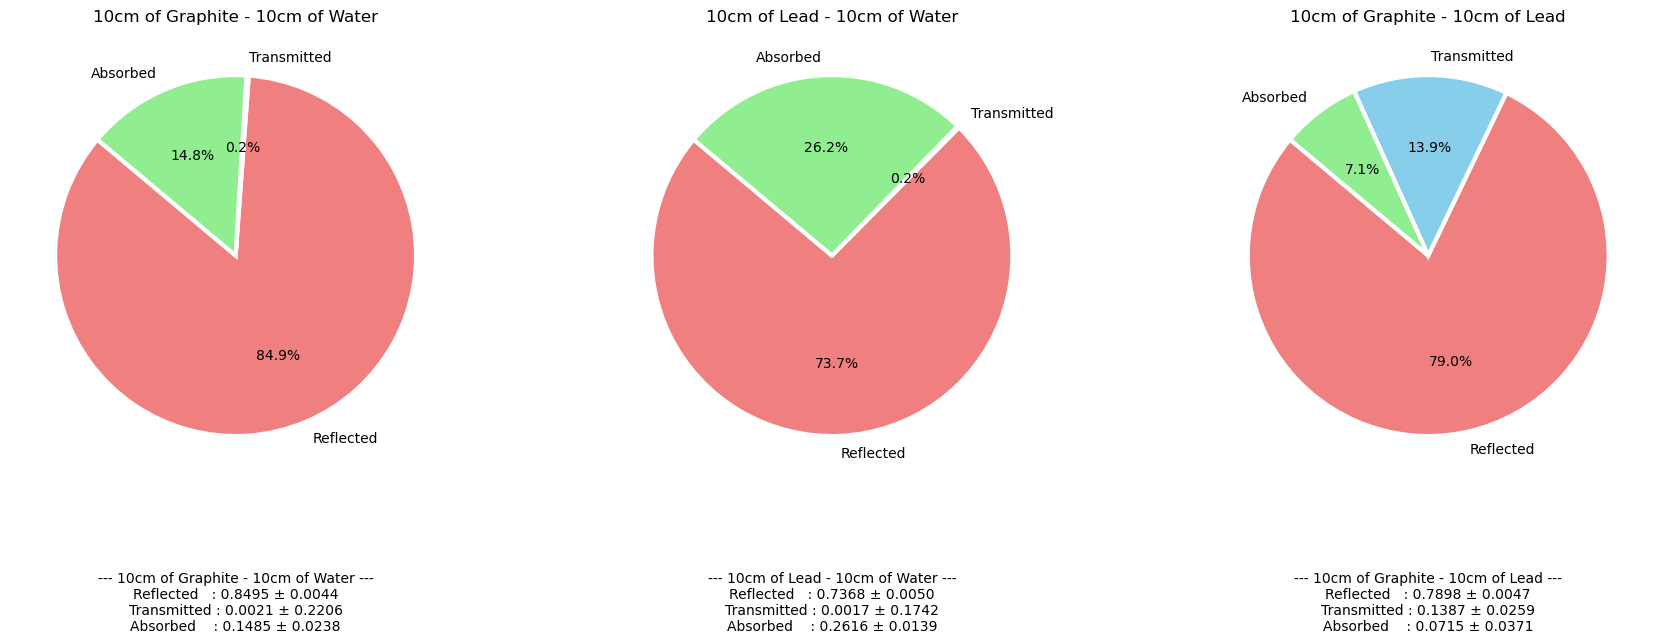

In [48]:
# Plotting the three scenarios rates with pie charts.
plot_three_pie_charts(two_slabs_titles_list, two_slabs_stats_list)

From these plots we can see that combination G-W and L-W have significantly low transmission rates, almost zero. As shown in section 3.3, the mean transmission rate for 10 cm of graphite is 30% and for 10cm of water it is 0.3%. Therefore we can see that our results make physical sense as it would be impossible to reach transmission rates greater than that of just 10cm of water (the same logic can be used for L-W too). We might even have expected a lower transmission rate than the function ```woodcock_n_iterations_rates``` gave us.

We can see that the absorption rate for G-W is lower than that of L-W, again making sense as 10cm of graphite has a lower absorption rate than 10cm of lead.

We can see the removal of water increases the the transmission rate, for G-L due to both graphite and lead having greater attenuation lengths. The absorption rate also decreases as graphite and lead both possess a much lower absorption probability.

All three scenarios have high reflection rates which is natural as the total length of the slab is now 20cm. 

# Conclusion.

In this notebook, we successfully developed a computational simulation to study neutron transport through various shielding materials using Monte Carlo techniques. We analysed how the thickness and type of shielding material influence the rates of absorption, reflection, and transmission of neutrons. 

Our results found major differences between the three materials: water, lead and graphite. For 10cm of water it possessed the lowest transmission rate (almost zero) but the highest absorption rate with graphite having the oppisite properties. The results returned were physically valid which suggests our method and function ```n_iterations_rates()``` are reliable.

By plotting the relationship of the rates with the thickness of the slab, we found the characteristic attenuation lengths for the three materials. Additionally we used the Woodcock method to successfully simulate neutron transport through multiple materials.

Due to the nature of Monte Carlo techniques, writing efficient code was crucial to minimising runtime. This can be seen in the improvement from ```simulate_neutron_rand_walk()``` to ```n_iterations_rates()``` and ```woodcock_n_iterations_rates()```.

Overall, this project clearly illustrated the use of Monte Carlo simulations when analysing neutron transport. Its results offer insights into shielding against neutrons.